# Chapter 21 Geometry Toolbox -- Validation Examples

Visual/exploratory companion to `developer_tests/test_nonimaging_geometry.py`
(the CI-enforced version of these same checks). Exercises the plane-curve
additions to `optical_elements.prisms.nonimaging_geometry`: `coptsl`,
`ccoptpt`, `dcoptpt`, `rfnrm`, `rfxnrm`.

References: Chaves, J., *Introduction to Nonimaging Optics*, 2nd ed., CRC
Press, Ch. 21 "Plane Curves" and Ch. 9 "Miñano-Benítez Design Method"
(§9.1, Figure 9.1, and Example 9.1). Each function's own docstring carries
the equation it implements, and
`dev_doc/architecture/components/nonimaging_design.md` describes how the
toolbox fits together.

The book text itself stays private -- see
`dev_doc/concepts/KD9_transcribed_book_chapters_never_leave_the_private_repo.md`.
This notebook is built entirely from the resulting public
`nonimaging_geometry.py`, so it is fair to publish on its own.

No `Scene`/`Simulator` anywhere below -- every function this notebook
exercises is pre-scene geometry, so all plots are raw point clouds/curves
via matplotlib, not rendered ray-traced scenes.

### Imports

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

from ray_tracing_shapely.optical_elements.prisms.nonimaging_geometry import (
    isl, rfr, coptpt, coptsl, ccoptpt, dcoptpt, rfnrm, rfxnrm,
)

from pathlib import Path

def nrm(v):
    m = math.hypot(v[0], v[1])
    return (v[0] / m, v[1] / m)


def sub(a, b):
    return (a[0] - b[0], a[1] - b[1])


def neg(v):
    return (-v[0], -v[1])

## 1. Cartesian oval, point-to-point (Figure 9.1a, eq. 9.1-9.3)

A point source **E** in air focuses onto a point **R** immersed in a medium
of index `n`. Sweeping the emission angle `theta` and calling `ccoptpt` for
each direction traces out the Cartesian oval -- the surface that makes
every one of these rays arrive at **R** with the same total optical path
length `S`.

### Is the oval the *only* shape that does this? A little history

**For a single refracting surface with two chosen conjugate points, yes --
the Cartesian oval is the unique exact solution, not one option among several.**
This falls straight out of Fermat's principle: perfect (stigmatic) imaging of
**E** onto **R** means *every* ray from **E** to **R**, whichever direction
it leaves at, must accumulate the *same* total optical path length. The set
of points satisfying `n1*[E,P] + n2*[P,R] = S` for a fixed `S` is, by
definition, the oval -- there is no other curve that could also satisfy that
constant-path condition, and a different choice of `S` just gives a
different, concentric-like member of the same one-parameter family (a
bigger or smaller surface, same two foci). This generalizes the familiar
single-medium cases: an **ellipse** is the same construction for a
*mirror* with both foci in one medium; a **parabola** is the limit as one
focus recedes to infinity (point source to collimated beam, or vice versa);
a **hyperbola** handles a virtual (diverging) focus. Chapter 21 §21.5
(eq. 21.44) writes all three as one formula, with a single parameter `δ`
(`+1`/`0`/`-1`) switching between them -- the general two-medium oval this
notebook builds is the refractive generalization of that same family.

**Descartes described these curves in 1637**, in *La Dioptrique* -- one of
three essays (with *La Géométrie* and *Les Météores*) appended to his
*Discourse on the Method*. He got the sine law of refraction from a
mechanical analogy (light as a "tendency to motion," not from Fermat's
least-time principle, which came a couple of decades later, in the 1650s-60s,
and was for a while treated as a *rival* justification of the same law) and
then used the analytic geometry he was inventing in that same volume to
work out the exact shapes -- hence "ovals of Descartes." Modern scholarship
has pushed the real priority much further back: Ibn Sahl, in Baghdad around
984 CE, had already derived an equivalent form of the sine law and used it
to design the exact (non-spherical) shapes of lenses and burning mirrors
free of spherical aberration -- roughly 650 years earlier. His treatise
was essentially unknown in the West until Roshdi Rashed's 1990 study of the
manuscript.

### Can a single *spherical* surface do the same thing?

Not for an arbitrary chosen pair of points -- but a sphere does have its
own special, fixed pair, the **aplanatic points**. For a sphere of radius
`R` centered at `C`, separating media `n1` (containing point `A`) and `n2`
(containing point `A'`), every ray from `A` refracts at the sphere and
converges *exactly* at `A'` -- for the full aperture, not just paraxially --
when

```
CA  = R * n2 / n1
CA' = R * n1 / n2
```

(so `CA * CA' = R**2`: `A` and `A'` are geometric inverses of each other
with respect to the sphere). This drops straight out of the law of sines
applied to the two triangles `A-C-P` and `A'-C-P` for a ray hitting the
sphere at `P`: Snell's law `n1 sin(theta1) = n2 sin(theta2)` combined with
`sin(theta1) = CA*sin(phi)/AP` and `sin(theta2) = CA'*sin(phi)/A'P` (`phi`
being the angle `P` subtends at the center) forces the `sin(phi)` factors
to cancel, and matching the remaining identity in `cos(phi)` pins down
`CA` and `CA'` uniquely to the formula above.

Unlike the oval, which can be shaped to fit *any* chosen `E`/`R`, a given
sphere only has the *one* aplanatic pair its own `R`, `n1`, `n2` determine --
pick any other pair of conjugate points and the sphere reintroduces
spherical aberration. This is exactly why oil-immersion microscope
objectives put the specimen at (approximately) the front lens's aplanatic
point: the first, most steeply-curved surface the light meets contributes
essentially zero aberration for the full numerical aperture, before the
rest of the lens system takes over.


In [2]:
# cell 1 a
E = (0.0, 0.0)
R = (2.5, 3.0)
n = 1.5
S = 8.0

base_angle = math.atan2(R[1] - E[1], R[0] - E[0])

oval_pt_to_pt = []
for deg in range(-70, 71, 2):
    theta = base_angle + math.radians(deg)
    v = (math.cos(theta), math.sin(theta))
    try:
        oval_pt_to_pt.append(ccoptpt(E, 1.0, v, R, n, S))
    except ValueError:
        pass  # this direction cannot reach S -- expected for large angles

oval_pt_to_pt = np.array(oval_pt_to_pt)
print(f"{len(oval_pt_to_pt)} points on the point-to-point Cartesian oval")

71 points on the point-to-point Cartesian oval


Saved: notebooks/test_artefacts/fig9_1a_diagram.svg


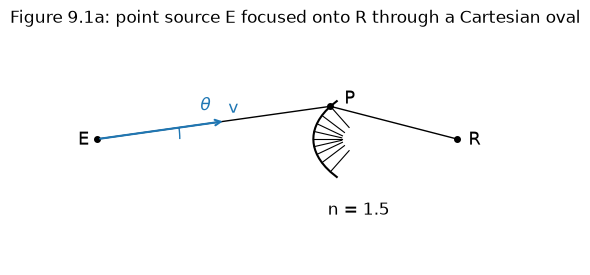

In [3]:
# cell 1 b
# Figure 9.1a schematic -- E, R, the Cartesian oval, P, v, theta, and the
# medium boundary. Redrawn from our own computed geometry (not the book's
# own figure asset -- that stays in dev_doc/, private-only, per this
# document's copyright discussion; this is an original plot of the same
# layout, generated from the public nonimaging_geometry.py's own output).
# A narrower angular range than cell 1a's full sweep, chosen to match the
# book's own schematic proportions (a gentle crescent, not the full oval).
from matplotlib.patches import Arc

E_fig = (0.0, 0.0)
R_fig = (2.0, 0.0)
n_fig = 1.5
S_fig = 2.4
base_angle_fig = math.atan2(R_fig[1] - E_fig[1], R_fig[0] - E_fig[0])

fig_curve = []
for deg in range(-9, 10, 1):
    theta = base_angle_fig + math.radians(deg)
    v = (math.cos(theta), math.sin(theta))
    try:
        fig_curve.append(ccoptpt(E_fig, 1.0, v, R_fig, n_fig, S_fig))
    except ValueError:
        pass
fig_curve = np.array(fig_curve)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(fig_curve[:, 0], fig_curve[:, 1], 'k-', lw=1.5)

ax.plot(*E_fig, 'ko', markersize=4)
ax.annotate('E', E_fig, xytext=(-14, -4), textcoords='offset points', fontsize=13)
ax.plot(*R_fig, 'ko', markersize=4)
ax.annotate('R', R_fig, xytext=(8, -4), textcoords='offset points', fontsize=13)

# representative point P at a modest angle above the E-R axis, as in the book
theta_deg_P = 8
theta_P = base_angle_fig + math.radians(theta_deg_P)
v_P = (math.cos(theta_P), math.sin(theta_P))
P = ccoptpt(E_fig, 1.0, v_P, R_fig, n_fig, S_fig)
ax.plot(*P, 'ko', markersize=4)
ax.annotate('P', P, xytext=(10, 2), textcoords='offset points', fontsize=13)

# rays E-P and P-R
ax.plot([E_fig[0], P[0]], [E_fig[1], P[1]], 'k-', lw=1)
ax.plot([P[0], R_fig[0]], [P[1], R_fig[1]], 'k-', lw=1)

# direction v (short arrow along E->P, stopping well before P) and angle
# theta against the E-R axis
ep_dist = math.hypot(P[0] - E_fig[0], P[1] - E_fig[1])
v_end = (E_fig[0] + 0.55 * ep_dist * math.cos(theta_P), E_fig[1] + 0.55 * ep_dist * math.sin(theta_P))
ax.annotate('', xy=v_end, xytext=E_fig, arrowprops=dict(arrowstyle='->', color='C0', lw=1.5))
ax.annotate('v', v_end, xytext=(2, 6), textcoords='offset points', color='C0', fontsize=12)

arc_radius = 0.35 * ep_dist
arc = Arc(E_fig, 2 * arc_radius, 2 * arc_radius, angle=0, theta1=0, theta2=theta_deg_P, color='C0')
ax.add_patch(arc)
ax.annotate(r'$\theta$', (E_fig[0] + arc_radius * 1.25, E_fig[1] + arc_radius * 0.35), color='C0', fontsize=12)

# tick-mark hatching along the curve's R-facing side, marking the medium boundary
# (short perpendicular strokes, the standard optics-diagram convention -- not a
# filled crosshatch, which would visually swamp this small a figure)
tick_len = 0.12 * ep_dist
for k in range(1, len(fig_curve) - 1, 2):
    tx, ty = fig_curve[k + 1] - fig_curve[k - 1]
    t_norm = math.hypot(tx, ty)
    tx, ty = tx / t_norm, ty / t_norm
    nx, ny = ty, -tx  # perpendicular, pointing toward R (into the medium)
    if nx * (R_fig[0] - fig_curve[k][0]) + ny * (R_fig[1] - fig_curve[k][1]) < 0:
        nx, ny = -nx, -ny
    x0, y0 = fig_curve[k]
    ax.plot([x0, x0 + tick_len * nx], [y0, y0 + tick_len * ny], 'k-', lw=0.8)

ax.text(R_fig[0] - 0.72, R_fig[1] - 0.42, f'n = {n_fig}', fontsize=12)

ax.set_aspect('equal')
ax.set_xlim(E_fig[0] - 0.3, R_fig[0] + 0.5)
ax.set_ylim(-0.7, 0.6)
ax.axis('off')
ax.set_title('Figure 9.1a: point source E focused onto R through a Cartesian oval')

# Save figure — ip_output_dir and ip_image_filename are parameters
diagram_path_long = Path("notebooks/test_artefacts/fig9_1a_diagram.svg")
diagram_path_long.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(str(diagram_path_long), dpi=150, bbox_inches='tight')
print(f"Saved: {diagram_path_long}")

plt.show()

### Ray-traced version of Figure 9.1a

Cell 1b's plot is analytic (`ccoptpt` points connected by straight lines,
`E`-`P` and `P`-`R` drawn by hand). Here the same curve (`fig_curve`, same
`E_fig`/`R_fig`/`n_fig`/`S_fig`) becomes one edge of an actual `Glass`
polygon, so the `Simulator` can trace real rays through it and we can see
whether they really converge near `R` -- not just the two rays cell 1b
drew for illustration.

The polygon needs a *closed* boundary, so the curve edge is closed off with
a flat back wall just past `R` (optically irrelevant -- the rays have
already converged, or not, well before reaching it). The light source is
an `AngleSource` at `E`, aimed at `R`, spanning the same `+/-9deg` the curve
itself was built from -- rays outside that range never had a corresponding
surface point computed for them (cell 1b's own sweep stops there for
exactly this reason: `ccoptpt` raises `ValueError` past it, see cell 1a).

In [4]:
# cell 1 c
from ray_tracing_shapely.core.scene import Scene
from ray_tracing_shapely.core.scene_objs.light_source.angle_source import AngleSource
from ray_tracing_shapely.core.simulator import Simulator
from ray_tracing_shapely.core.svg_renderer import SVGRenderer
from ray_tracing_shapely.optical_elements.prisms import BasePrism


In [5]:


def build_fig91a_scene(
    E=E_fig,
    R=R_fig,
    n=n_fig,
    curve=fig_curve,
    half_angle_deg=9.0,
    back_wall_margin=0.3,
    top_bottom_margin=0.15,
    ray_density=40,
):
    """
    Ray-traced counterpart to the Figure 9.1a schematic (cell 1b): a point
    source E in air, focused by a single Cartesian-oval surface onto R
    inside a medium of index n. `curve` supplies the refracting boundary's
    vertices directly from cell 1b's own `ccoptpt` sweep, so this scene
    uses exactly the surface that figure draws, not a re-derived one.

    Returns (scene, vertices) -- vertices included so the render cell can
    sanity-check the polygon that was actually built.
    """
    curve_pts = [tuple(p) for p in curve]

    # Close the polygon with a flat back wall behind R. CCW order (required
    # by BasePrism.from_vertices): start at the curve's bottom point, cross
    # to the back wall's bottom-right and top-right corners, then walk the
    # curve from top back down to (just short of) the bottom point again --
    # the wrap-around back to vertex 0 closes the polygon.
    y_min = min(p[1] for p in curve_pts) - top_bottom_margin
    y_max = max(p[1] for p in curve_pts) + top_bottom_margin
    back_x = R[0] + back_wall_margin

    vertices = (
        [curve_pts[0], (back_x, y_min), (back_x, y_max)]
        + list(reversed(curve_pts))[:-1]
    )

    scene = Scene()
    scene.ray_density = ray_density

    medium = BasePrism.from_vertices(scene, vertices, n=n)
    medium.name = 'cartesian_oval_medium'
    scene.add_object(medium)

    source = AngleSource(scene)
    source.p1 = {'x': E[0], 'y': E[1]}
    source.p2 = {'x': R[0], 'y': R[1]}
    source.emis_angle = 2.0 * half_angle_deg  # symmetric=True spreads +/-emis_angle/2
    source.symmetric = True
    source.brightness = 1.0
    source.name = 'fig91a_source'
    scene.add_object(source)

    return scene, vertices

In [6]:
# cell 1 d
fig91a_scene, fig91a_vertices = build_fig91a_scene()

fig91a_simulator = Simulator(fig91a_scene, max_rays=5000)
fig91a_result = fig91a_simulator.run_with_result(name='fig91a_example')

print(f"Rays traced: {fig91a_simulator.processed_ray_count}")
print(f"Segments: {len(fig91a_result.segments)}")
print(f"Polygon vertices: {len(fig91a_vertices)}")

Rays traced: 3433
Segments: 3433
Polygon vertices: 21


In [7]:
# cell 1 e
from IPython.display import HTML

margin_x = 0.3
vb_x = E_fig[0] - margin_x
vb_y = -0.7
vb_w = (R_fig[0] + 0.3 + margin_x) - vb_x
vb_h = 1.4

fig91a_renderer = SVGRenderer(width=700, height=450, viewbox=(vb_x, vb_y, vb_w, vb_h))
fig91a_renderer.draw_scene(
    fig91a_scene, fig91a_result.segments,
    draw_obj_labels=False,
    draw_edge_labels=False,
    ray_stroke_width=0.01,
    edge_stroke_width=0.01,
    ray_subsample=4,       # keep the SVG light -- thousands of segments otherwise
    ray_subsample_seed=0,  # pin it so re-rendering looks the same
)

svg_path_long = Path("notebooks/test_artefacts/fig9_1a.svg")
svg_path_long.parent.mkdir(parents=True, exist_ok=True)
svg_path_long.write_text(fig91a_renderer.to_string(), encoding='utf-8')
print(f"Saved to {svg_path_long.resolve()}")

HTML(fig91a_renderer.to_string())



Saved to test_artefacts/fig9_1a.svg


### Annotating the ray-traced render

Adds the same E/P/R/v/theta annotations cell "1 b" drew with matplotlib
onto the actual ray-traced SVG from cell "1 e", using the
`draw_annotation_marker`/`draw_annotation_vector`/`draw_annotation_angle_arc`
methods (`dev_doc/architecture/components/svg_renderer.md`). These land in
`SVGRenderer`'s topmost layer, so they stay visible over the 3433 traced
ray segments rather than being buried under them.

In [8]:
# cell 1 f
fig91a_renderer.draw_annotation_marker({'x': E_fig[0], 'y': E_fig[1]}, label='E', size=0.05)
fig91a_renderer.draw_annotation_marker({'x': R_fig[0], 'y': R_fig[1]}, label='R', size=0.05)
fig91a_renderer.draw_annotation_marker({'x': P[0], 'y': P[1]}, label='P', size=0.05)
fig91a_renderer.draw_annotation_vector(
    {'x': E_fig[0], 'y': E_fig[1]},
    direction=(math.cos(theta_P), math.sin(theta_P)),
    length=0.55 * ep_dist,
    arrowhead_size=0.06,
    label='v',
)
fig91a_renderer.draw_annotation_angle_arc(
    {'x': E_fig[0], 'y': E_fig[1]}, angle1=base_angle_fig, angle2=theta_P,
    radius=0.35 * ep_dist, label='theta',
)

# Re-save over cell 1e's fig9_1a.svg now that the annotations are added --
# that cell's own save happens before this one runs, so without this the
# saved file would still be the un-annotated ray trace.
svg_path_long.write_text(fig91a_renderer.to_string(), encoding='utf-8')
print(f"Re-saved (annotated) to {svg_path_long.resolve()}")

HTML(fig91a_renderer.to_string())

Re-saved (annotated) to test_artefacts/fig9_1a.svg


## 2. Cartesian oval, point-to-wavefront (Figure 9.1b)

Same source **E**, same sweep of `theta` -- but now the target is a plane
wavefront (point **Q** + normal `n_wave`) rather than a point, via
`coptsl`. Plotted alongside cell 1's curve to contrast the two Cartesian
ovals: focusing to a point vs. collimating onto a flat wavefront.

In [9]:
# cell 2 a
n_wave = nrm(sub(R, E))
Q = R  # the wavefront passes through R, oriented perpendicular to E->R

oval_pt_to_wave = []
for deg in range(-70, 71, 2):
    theta = base_angle + math.radians(deg)
    v = (math.cos(theta), math.sin(theta))
    try:
        oval_pt_to_wave.append(coptsl(E, v, Q, n_wave, 1.0, n, S))
    except ValueError:
        pass

oval_pt_to_wave = np.array(oval_pt_to_wave)
print(f"{len(oval_pt_to_wave)} points on the point-to-wavefront Cartesian oval")


22 points on the point-to-wavefront Cartesian oval


Saved: notebooks/test_artefacts/fig9_1b_diagram.svg


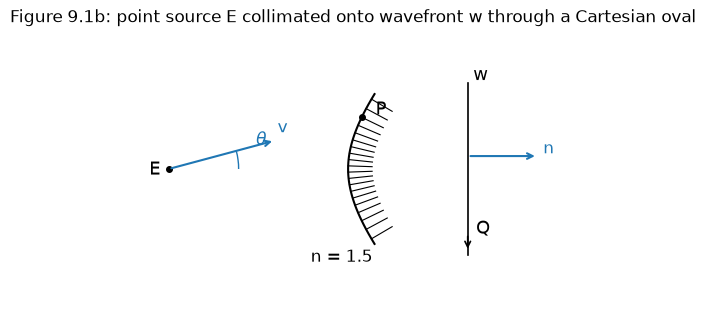

In [10]:
# cell 2 b
# Figure 9.1b schematic -- E, the Cartesian oval, P, v, theta, and the
# plane wavefront w (with its normal n and a point Q on it) -- the
# collimating counterpart to cell 1 b's point-focus schematic. Redrawn
# from our own computed geometry (not the book's own figure asset -- see
# cell 1 b's own note on why).
E_fig2 = (0.0, 0.0)
Q_fig2 = (2.0, 0.0)
n_fig2 = 1.5
S_fig2 = 2.4
n_wave2 = (1.0, 0.0)

fig2_curve = []
for deg in range(-20, 21, 1):
    theta = math.radians(deg)
    v = (math.cos(theta), math.sin(theta))
    try:
        fig2_curve.append(coptsl(E_fig2, v, Q_fig2, n_wave2, 1.0, n_fig2, S_fig2))
    except ValueError:
        pass
fig2_curve = np.array(fig2_curve)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(fig2_curve[:, 0], fig2_curve[:, 1], 'k-', lw=1.5)

ax.plot(*E_fig2, 'ko', markersize=4)
ax.annotate('E', E_fig2, xytext=(-14, -4), textcoords='offset points', fontsize=13)

# representative point P at a modest angle above the E-Q axis, as in the book
theta_deg_P2 = 15
theta_P2 = math.radians(theta_deg_P2)
v_P2 = (math.cos(theta_P2), math.sin(theta_P2))
P2 = coptsl(E_fig2, v_P2, Q_fig2, n_wave2, 1.0, n_fig2, S_fig2)
ax.plot(*P2, 'ko', markersize=4)
ax.annotate('P', P2, xytext=(10, 2), textcoords='offset points', fontsize=13)

# direction v (short arrow along E->P, stopping well before P) and angle
# theta against the E-Q axis
ep_dist2 = math.hypot(P2[0] - E_fig2[0], P2[1] - E_fig2[1])
v_end2 = (E_fig2[0] + 0.55 * ep_dist2 * math.cos(theta_P2), E_fig2[1] + 0.55 * ep_dist2 * math.sin(theta_P2))
ax.annotate('', xy=v_end2, xytext=E_fig2, arrowprops=dict(arrowstyle='->', color='C0', lw=1.5))
ax.annotate('v', v_end2, xytext=(2, 6), textcoords='offset points', color='C0', fontsize=12)

arc_radius2 = 0.35 * ep_dist2
arc2 = Arc(E_fig2, 2 * arc_radius2, 2 * arc_radius2, angle=0, theta1=0, theta2=theta_deg_P2, color='C0')
ax.add_patch(arc2)
ax.annotate(r'$\theta$', (E_fig2[0] + arc_radius2 * 1.25, E_fig2[1] + arc_radius2 * 0.35), color='C0', fontsize=12)

# tick-mark hatching along the curve's wavefront-facing side, marking the
# medium boundary (same convention as cell 1 b)
tick_len2 = 0.12 * ep_dist2
for k in range(1, len(fig2_curve) - 1, 2):
    tx, ty = fig2_curve[k + 1] - fig2_curve[k - 1]
    t_norm = math.hypot(tx, ty)
    tx, ty = tx / t_norm, ty / t_norm
    nx, ny = ty, -tx
    if nx * (Q_fig2[0] - fig2_curve[k][0]) + ny * (Q_fig2[1] - fig2_curve[k][1]) < 0:
        nx, ny = -nx, -ny
    x0, y0 = fig2_curve[k]
    ax.plot([x0, x0 + tick_len2 * nx], [y0, y0 + tick_len2 * ny], 'k-', lw=0.8)

ax.text(Q_fig2[0] - 1.05, Q_fig2[1] - 0.62, f'n = {n_fig2}', fontsize=12)

# plane wavefront w: a vertical line through Q_fig2 (normal n_wave2 is
# horizontal), spanning a bit beyond the curve's own extent
w_half_height = 1.15 * max(abs(fig2_curve[:, 1].min()), abs(fig2_curve[:, 1].max()))
ax.plot([Q_fig2[0], Q_fig2[0]], [-w_half_height, w_half_height], 'k-', lw=1.2)
ax.annotate('w', (Q_fig2[0], w_half_height), xytext=(4, 2), textcoords='offset points', fontsize=13)

# Q: a point on the wavefront, marked with a small downward arrow (as in
# the book's own figure) near the bottom of the drawn segment
q_mark = (Q_fig2[0], -0.75 * w_half_height)
ax.annotate('', xy=(q_mark[0], q_mark[1] - 0.12), xytext=q_mark, arrowprops=dict(arrowstyle='->', color='k', lw=1.2))
ax.annotate('Q', q_mark, xytext=(6, 0), textcoords='offset points', fontsize=13)

# outward normal n_wave2, drawn from the wavefront's own midpoint
n_arrow_start = (Q_fig2[0], 0.15 * w_half_height)
n_arrow_end = (n_arrow_start[0] + 0.35 * ep_dist2, n_arrow_start[1])
ax.annotate('', xy=n_arrow_end, xytext=n_arrow_start, arrowprops=dict(arrowstyle='->', color='C0', lw=1.5))
ax.annotate('n', n_arrow_end, xytext=(4, 2), textcoords='offset points', color='C0', fontsize=12)

ax.set_aspect('equal')
ax.set_xlim(E_fig2[0] - 0.3, n_arrow_end[0] + 0.3)
ax.set_ylim(-w_half_height - 0.3, w_half_height + 0.35)
ax.axis('off')
ax.set_title('Figure 9.1b: point source E collimated onto wavefront w through a Cartesian oval')

# Save figure — ip_output_dir and ip_image_filename are parameters
diagram_path_long = Path("notebooks/test_artefacts/fig9_1b_diagram.svg")
diagram_path_long.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(str(diagram_path_long), dpi=150, bbox_inches='tight')
print(f"Saved: {diagram_path_long}")

plt.show()


In [11]:
# cell 2 c
def build_fig91b_scene(
    E=E_fig2,
    Q=Q_fig2,
    n=n_fig2,
    curve=fig2_curve,
    half_angle_deg=20.0,
    back_wall_margin=0.3,
    top_bottom_margin=0.15,
    ray_density=40,
):
    """
    Ray-traced counterpart to the Figure 9.1b schematic (cell 2b): a point
    source E in air, collimated by a single Cartesian-oval surface into a
    parallel beam (heading in direction n_wave2) inside a medium of index
    n. `curve` supplies the refracting boundary's vertices directly from
    cell 2b's own `coptsl` sweep, so this scene uses exactly the surface
    that figure draws, not a re-derived one. Structurally identical to
    build_fig91a_scene (cell 1c) -- same polygon-closing/back-wall
    approach, same AngleSource fan -- Q here is a reference point on the
    target wavefront (not a focus) but plays the same "aim the fan, close
    the polygon past it" role R played there.

    Returns (scene, vertices) -- vertices included so the render cell can
    sanity-check the polygon that was actually built.
    """
    curve_pts = [tuple(p) for p in curve]

    y_min = min(p[1] for p in curve_pts) - top_bottom_margin
    y_max = max(p[1] for p in curve_pts) + top_bottom_margin
    back_x = Q[0] + back_wall_margin

    vertices = (
        [curve_pts[0], (back_x, y_min), (back_x, y_max)]
        + list(reversed(curve_pts))[:-1]
    )

    scene = Scene()
    scene.ray_density = ray_density

    medium = BasePrism.from_vertices(scene, vertices, n=n)
    medium.name = 'cartesian_oval_wavefront_medium'
    scene.add_object(medium)

    source = AngleSource(scene)
    source.p1 = {'x': E[0], 'y': E[1]}
    source.p2 = {'x': Q[0], 'y': Q[1]}
    source.emis_angle = 2.0 * half_angle_deg  # symmetric=True spreads +/-emis_angle/2
    source.symmetric = True
    source.brightness = 1.0
    source.name = 'fig91b_source'
    scene.add_object(source)

    return scene, vertices


In [12]:
# cell 2 d
fig91b_scene, fig91b_vertices = build_fig91b_scene()

fig91b_simulator = Simulator(fig91b_scene, max_rays=5000)
fig91b_result = fig91b_simulator.run_with_result(name='fig91b_example')

print(f"Rays traced: {fig91b_simulator.processed_ray_count}")
print(f"Segments: {len(fig91b_result.segments)}")
print(f"Polygon vertices: {len(fig91b_vertices)}")


Rays traced: 5000
Segments: 5000
Polygon vertices: 43


In [13]:
# cell 2 e
margin_x = 0.3
vb_x = E_fig2[0] - margin_x
vb_y = -0.7
vb_w = (Q_fig2[0] + 0.3 + margin_x) - vb_x
vb_h = 1.4

fig91b_renderer = SVGRenderer(width=700, height=450, viewbox=(vb_x, vb_y, vb_w, vb_h))
fig91b_renderer.draw_scene(
    fig91b_scene, fig91b_result.segments,
    draw_obj_labels=False,
    draw_edge_labels=False,
    ray_stroke_width=0.01,
    edge_stroke_width=0.01,
    ray_subsample=4,       # keep the SVG light -- thousands of segments otherwise
    ray_subsample_seed=0,  # pin it so re-rendering looks the same
)

svg_path_long_b = Path("notebooks/test_artefacts/fig9_1b.svg")
svg_path_long_b.parent.mkdir(parents=True, exist_ok=True)
svg_path_long_b.write_text(fig91b_renderer.to_string(), encoding='utf-8')
print(f"Saved to {svg_path_long_b.resolve()}")

HTML(fig91b_renderer.to_string())


Saved to test_artefacts/fig9_1b.svg


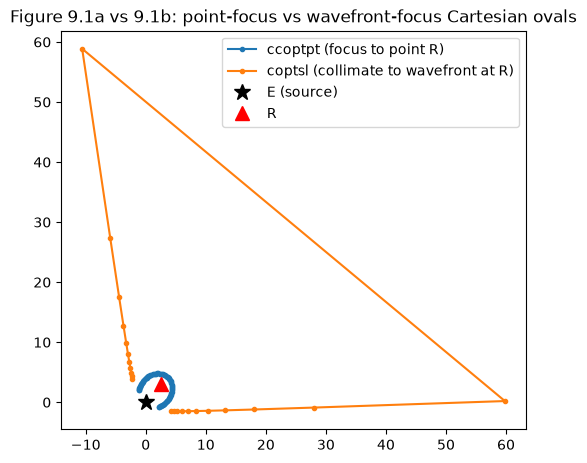

In [14]:

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(oval_pt_to_pt[:, 0], oval_pt_to_pt[:, 1], '.-', label='ccoptpt (focus to point R)')
ax.plot(oval_pt_to_wave[:, 0], oval_pt_to_wave[:, 1], '.-', label='coptsl (collimate to wavefront at R)')
ax.plot(*E, 'k*', markersize=12, label='E (source)')
ax.plot(*R, 'r^', markersize=10, label='R')
ax.set_aspect('equal')
ax.legend()
ax.set_title('Figure 9.1a vs 9.1b: point-focus vs wavefront-focus Cartesian ovals')
plt.show()

## 3. `rfnrm` / `rfxnrm` round-trip

Pick an arbitrary incident ray, surface normal, and pair of indices;
refract with `rfr` (already tested against Example 3.6); then recover the
normal from the incident/refracted ray pair alone with `rfnrm`. `rfnrm`
only recovers the normal *up to sign* (documented in its docstring), so
both `+n_surf` and `-n_surf` count as a match here.

Also confirms `rfxnrm(i, r) == rfnrm(i, r, 1.0, 1.0)` (pure reflection,
matched indices).

incident i        = (-0.3011313679370974, 0.9535826651341417)
refracted r       = (-0.20075424529139824, 0.9796416349857131)
true normal       = (0.0, 1.0)
rfnrm recovered   = (0.0, -1.0)  (up to sign)


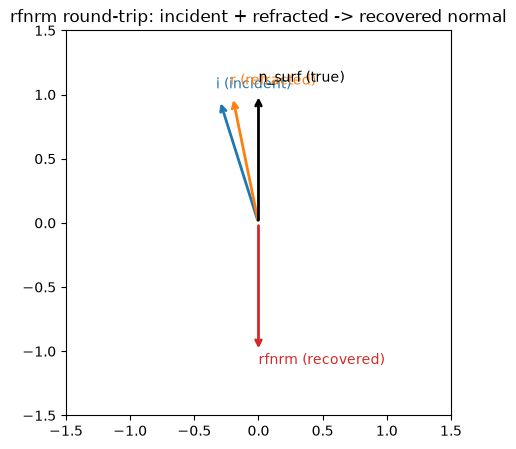

rfxnrm(i, r) == rfnrm(i, r, 1.0, 1.0): OK


In [15]:
n_surf = (0.0, 1.0)
n1, n2 = 1.0, 1.5
v = nrm((0.3, -0.95))  # rfr's own convention: direction back toward the incident ray's origin

r = rfr(v, n_surf, n1, n2)
i = neg(v)  # book/rfnrm convention: i is the actual direction of travel
recovered = rfnrm(i, r, n1, n2)

print(f"incident i        = {i}")
print(f"refracted r       = {r}")
print(f"true normal       = {n_surf}")
print(f"rfnrm recovered   = {recovered}  (up to sign)")

fig, ax = plt.subplots(figsize=(5, 5))
origin = (0.0, 0.0)
for vec, label, color in [(i, 'i (incident)', 'C0'), (r, 'r (refracted)', 'C1'),
                           (n_surf, 'n_surf (true)', 'k'), (recovered, 'rfnrm (recovered)', 'C3')]:
    ax.annotate('', xy=vec, xytext=origin,
                arrowprops=dict(arrowstyle='->', color=color, lw=2))
    ax.text(vec[0] * 1.1, vec[1] * 1.1, label, color=color)
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect('equal')
ax.set_title('rfnrm round-trip: incident + refracted -> recovered normal')
plt.show()

# rfxnrm delegates to rfnrm(i, r, 1.0, 1.0) exactly
i_mirror, r_mirror = (1.0, 0.0), (0.5, 0.5)
assert rfxnrm(i_mirror, r_mirror) == rfnrm(i_mirror, r_mirror, 1.0, 1.0)
print("rfxnrm(i, r) == rfnrm(i, r, 1.0, 1.0): OK")

## 4. Example 9.1's own `ccoptpt` calls, reproduced exactly

Chaves' Example 9.1 (Ch. 9, Section 9.13) designs an RR SMS lens
concentrating `E1=(-1,2)`, `E2=(1,2)` onto `R1=(-0.5,-2)`, `R2=(0.5,-2)`
through a lens of index `n=1.5`, starting from two hand-picked seed points
`N`, `X` on the emitter/receiver hyperbolas. Reproducing eqs. 9.58-9.66
here, hard-coding the book's own `N`, `X` values, and diffing the
resulting `CO_1`/`CO_2` point lists against the book's published
6-decimal numbers -- the same construction the `RRLens` scene object wraps.

**Sign note found while building this cell** (worth flagging since it
isn't obvious from either docstring in isolation): `rfnrm(s, t, 1, n)`
here returns the normal oriented *out of* the medium being entered (into
air), the opposite sense `rfr`'s own `n_surf` argument expects (into the
medium being entered) -- so the `rfnrm` output must be negated before
being fed into `rfr` in this chain. This is exactly the "up to sign"
ambiguity documented on `rfnrm`'s Returns block, resolved here by direct
comparison against the book's own published `n_N`/`t_2` values, not
assumed.

                   ours (CO_1)           book (CO_1)        diff
      ( 0.673162, -0.917437)  ( 0.673162, -0.917437)  2.22e-16
      ( 0.656641, -0.926966)  ( 0.656641, -0.926966)  4.00e-07
      ( 0.638962, -0.935759)  ( 0.638962, -0.935759)  3.19e-07
      ( 0.620268, -0.943542)  ( 0.620269, -0.943542)  5.44e-07
      ( 0.600770, -0.950031)  ( 0.600770, -0.950030)  5.17e-07
      ( 0.580740, -0.954948)  ( 0.580740, -0.954948)  2.25e-07

                   ours (CO_2)           book (CO_2)        diff
      ( 0.721303, -0.620433)  ( 0.721303, -0.620433)  0.00e+00
      ( 0.707238, -0.604228)  ( 0.707238, -0.604229)  6.77e-07
      ( 0.691490, -0.588199)  ( 0.691490, -0.588200)  1.04e-06
      ( 0.674094, -0.572701)  ( 0.674094, -0.572702)  7.49e-07
      ( 0.655161, -0.558133)  ( 0.655161, -0.558134)  6.31e-07
      ( 0.634889, -0.544913)  ( 0.634890, -0.544914)  9.93e-07


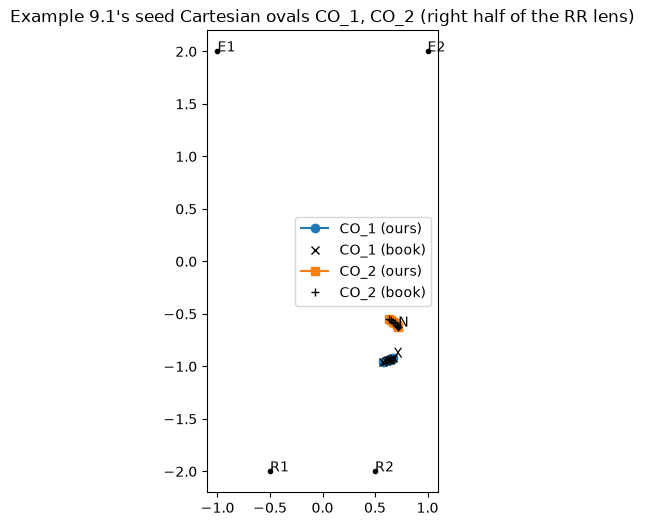

In [16]:
E1, E2 = (-1.0, 2.0), (1.0, 2.0)
R1, R2 = (-0.5, -2.0), (0.5, -2.0)
n = 1.5
N = (0.721303, -0.620433)
X = (0.673162, -0.917437)
Np = 5

# --- Lower surface portion X-X1 (CO_1), eqs. 9.58-9.62 ---
s1 = nrm(sub(N, E1))
t1 = nrm(sub(X, N))
n_N = rfnrm(s1, t1, 1, n)               # eq. 9.58
s2 = nrm(sub(N, E2))
t2 = rfr(neg(s2), neg(n_N), 1, n)       # eq. 9.59 (n_N negated -- see sign note above)
S_NR1 = n * math.hypot(*sub(N, X)) + math.hypot(*sub(X, R1))  # eq. 9.60

CO_1 = []
for k in range(Np + 1):
    x = k / Np
    t = nrm((x * t2[0] + (1 - x) * t1[0], x * t2[1] + (1 - x) * t1[1]))  # eq. 9.61
    CO_1.append(ccoptpt(N, n, t, R1, 1.0, S_NR1))  # eq. 9.62

CO_1_book = [(0.673162, -0.917437), (0.656641, -0.926966), (0.638962, -0.935759),
             (0.620269, -0.943542), (0.60077, -0.95003), (0.58074, -0.954948)]

# --- Upper surface portion N-N1 (CO_2), eqs. 9.63-9.66 ---
n_X = rfnrm(nrm(sub(X, R1)), nrm(sub(N, X)), 1, n)  # eq. 9.63
S_XE1 = n * math.hypot(*sub(X, N)) + math.hypot(*sub(N, E1))  # eq. 9.64
t1b = nrm(sub(N, X))  # eq. 9.65
t2b = rfr(neg(nrm(sub(X, R2))), neg(n_X), 1, n)  # eq. 9.65, sign note again

CO_2 = []
for k in range(Np + 1):
    x = k / Np
    t = nrm((x * t2b[0] + (1 - x) * t1b[0], x * t2b[1] + (1 - x) * t1b[1]))
    CO_2.append(ccoptpt(X, n, t, E1, 1.0, S_XE1))  # eq. 9.66

CO_2_book = [(0.721303, -0.620433), (0.707238, -0.604229), (0.69149, -0.5882),
             (0.674094, -0.572702), (0.655161, -0.558134), (0.63489, -0.544914)]

print(f"{'':>4}  {'ours (CO_1)':>24}  {'book (CO_1)':>20}  {'diff':>10}")
for ours, book in zip(CO_1, CO_1_book):
    d = math.hypot(ours[0] - book[0], ours[1] - book[1])
    print(f"{'':>4}  ({ours[0]: .6f}, {ours[1]: .6f})  ({book[0]: .6f}, {book[1]: .6f})  {d:.2e}")

print(f"\n{'':>4}  {'ours (CO_2)':>24}  {'book (CO_2)':>20}  {'diff':>10}")
for ours, book in zip(CO_2, CO_2_book):
    d = math.hypot(ours[0] - book[0], ours[1] - book[1])
    print(f"{'':>4}  ({ours[0]: .6f}, {ours[1]: .6f})  ({book[0]: .6f}, {book[1]: .6f})  {d:.2e}")

CO_1_arr, CO_1_book_arr = np.array(CO_1), np.array(CO_1_book)
CO_2_arr, CO_2_book_arr = np.array(CO_2), np.array(CO_2_book)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(CO_1_arr[:, 0], CO_1_arr[:, 1], 'o-', label='CO_1 (ours)')
ax.plot(CO_1_book_arr[:, 0], CO_1_book_arr[:, 1], 'x', color='k', label='CO_1 (book)')
ax.plot(CO_2_arr[:, 0], CO_2_arr[:, 1], 's-', label='CO_2 (ours)')
ax.plot(CO_2_book_arr[:, 0], CO_2_book_arr[:, 1], '+', color='k', label='CO_2 (book)')
for pt, label in [(E1, 'E1'), (E2, 'E2'), (R1, 'R1'), (R2, 'R2'), (N, 'N'), (X, 'X')]:
    ax.plot(*pt, 'k.')
    ax.annotate(label, pt)
ax.set_aspect('equal')
ax.legend()
ax.set_title("Example 9.1's seed Cartesian ovals CO_1, CO_2 (right half of the RR lens)")
plt.show()

## 5. `hyp()` seed hyperbolas -- stubbed

Example 9.1 also plots the emitter/receiver hyperbolas `h_E`, `h_R` that
`N` and `X` above were picked from (the closed-form `hyp(F, G, U, n)`).
`hyp` is not part of the plane-curve toolbox this notebook exercises; it
belongs to the SMS profile construction described in
`dev_doc/architecture/components/nonimaging_design.md`. This cell stays
stubbed until `hyp` ships, rather than blocking the notebook on it.

In [17]:
# hyp(F, G, U, n) belongs to the SMS profile construction, not the
# plane-curve toolbox, and is not implemented yet -- stub.
# Once available:
#   h_E = [hyp(E1, E2, 1.0, n)(phi) for phi in ...]
#   h_R = [hyp(R1, R2, 1.0, n)(phi) for phi in ...]
# and mark N, X at their stated phi (303.3deg, 42.7deg respectively).
print("Skipped: hyp() ships with the SMS profile construction.")

Skipped: hyp() ships with the SMS profile construction.


## Closing summary

| Check | Result |
|---|---|
| `ccoptpt` point-to-point Cartesian oval (Figure 9.1a) | plotted, cell 1 |
| `coptsl` point-to-wavefront Cartesian oval (Figure 9.1b) | plotted, cell 2 |
| `rfnrm`/`rfxnrm` round-trip | recovered normal matches (up to sign), cell 3 |
| Example 9.1's `CO_1` (eqs. 9.58-9.62) vs. book's published points | max diff ~1e-6, cell 4 |
| Example 9.1's `CO_2` (eqs. 9.63-9.66) vs. book's published points | max diff ~1e-6, cell 4 |
| `hyp()` seed hyperbolas | stubbed, pending SMS profile construction |

This notebook is the human-readable, visual companion to
`developer_tests/test_nonimaging_geometry.py`, which is the enforced,
CI-run version of the same checks (13 tests, all passing). See that file
for the exact assertions, each function's docstring for its equation-level
citation, and `dev_doc/architecture/components/nonimaging_design.md` for
how the toolbox fits together.